# ResNet-18 Transfer Learning: Ants vs. Bees

This project uses an ImageNet-pretrained ResNet-18 model in PyTorch to classify images of ants and bees. The backbone is frozen, and only a new two-class classifier is trained. The notebook covers data augmentation, training, learning curves, a confusion matrix, and single-image prediction.

The saved run uses 244 training images and 153 validation images, reaching **96.1% validation accuracy (147/153)** after four epochs. This is a recorded validation result, not an independent test-set score; results may vary between runs.

**Requirements:** Python, PyTorch, TorchVision, Matplotlib, and Pillow. Run the cells in order in Jupyter or Google Colab. Internet access is needed on the first run to download the dataset and pretrained weights; a CUDA GPU is optional.


In [2]:
from collections import Counter
# Counts how many ant and bee images are in each dataset split.
from pathlib import Path
# Builds file and folder paths and checks whether they exist.
from zipfile import ZipFile
#Opens and extracts the downloaded ants-and-bees dataset archive.

import matplotlib.pyplot as plt
#Displays images and plots learning curves and the confusion matrix
import torch
#Handles tensors, selects the CPU or GPU, and computes gradients during training.
import torchvision
# Lets the notebook print the installed TorchVision version.
from PIL import Image
# Opens image files and converts them to RGB for prediction or display.
from torch import nn
#Provides the new linear classifier and the cross-entropy loss function
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
# Loads images by class folder and applies image preprocessing.
from torchvision.models import ResNet18_Weights, resnet18
# Builds ResNet-18 with pretrained ImageNet weights.

SEED = 42
BATCH_SIZE = 16
EPOCHS = 4
LEARNING_RATE = 0.001

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
  torch.set_num_threads(min(4, torch.get_num_threads()))

print("Device:", device)
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)

Device: cuda
PyTorch: 2.14.1+cu130
TorchVision: 0.29.1+cu130


In [7]:
DATA_URL = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
archive_path = Path("hymenoptera_data.zip")
data_dir = Path("hymenoptera_data")

if not all((data_dir / split).is_dir() for split in ("train", "val")):
   if not archive_path.exists():
      print("Downloading the ants and bees dataset...")
      torch.hub.download_url_to_file(DATA_URL, str(archive_path), progress=False)
   with ZipFile(archive_path) as archive:
      archive.extractall(data_dir.parent)

for split in ("train", "val"):
  print(f"{split}: {data_dir / split}")

train: hymenoptera_data/train
val: hymenoptera_data/val


**Step 3:** Prepare images and create data loaders

In [11]:
# Select the ImageNet-1K pretrained weights to use when building ResNet-18 later.
weights = ResNet18_Weights.IMAGENET1K_V1
# Get the preprocessing that matches these weights: resize the shorter side to 256,
# center-crop to 224 × 224, convert to a tensor, and normalize each color channel.
val_transform = weights.transforms()

# Apply the following training transforms in order whenever an image is loaded.
train_transform = transforms.Compose([
# Randomly crop 80%–100% of the original image area, then resize to 224 × 224.
transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
# Flip the image left to right with a 50% chance.
transforms.RandomHorizontalFlip(),
# Convert the RGB image to a [3, 224, 224] tensor and scale pixels from 0–255 to 0–1.
transforms.ToTensor(),
# Normalize each RGB channel using the mean and standard deviation expected by ResNet-18.
transforms.Normalize(mean=val_transform.mean, std=val_transform.std),
])

# Use the subfolder names as labels and apply random augmentation to training images.
train_dataset = datasets.ImageFolder(data_dir / "train", transform=train_transform)
val_dataset = datasets.ImageFolder(data_dir / "val", transform=val_transform)

# Get the class names in label-ID order: ["ants", "bees"].
class_names = train_dataset.classes
assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert set(class_names) == {"ants", "bees"}

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Class IDs:", train_dataset.class_to_idx)
for split, dataset in [("Train", train_dataset), ("Validation", val_dataset)]:
  counts = Counter(class_names[label] for label in dataset.targets)
  print(f"{split}: {len(dataset)} images, {dict(counts)}")

Class IDs: {'ants': 0, 'bees': 1}
Train: 244 images, {'ants': 123, 'bees': 121}
Validation: 153 images, {'ants': 70, 'bees': 83}


**Step 4:** Inspect an image batch

Image tensor shape: [16, 3, 224, 224]
Label tensor shape: [16]
First four class IDs: [1, 0, 0, 0]


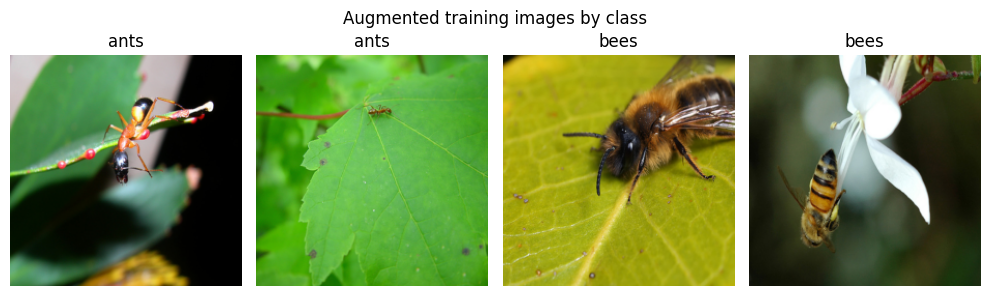

In [14]:
images, labels = next(iter(train_loader))
print("Image tensor shape:", list(images.shape))
print("Label tensor shape:", list(labels.shape))
print("First four class IDs:", labels[:4].tolist())

# Reshape the three RGB means to [3, 1, 1] so each mean applies to its whole channel.
mean = torch.tensor(val_transform.mean).view(3, 1, 1)
# Reshape the three RGB standard deviations the same way.
std = torch.tensor(val_transform.std).view(3, 1, 1)

# Pair each plot in the first row (axes[0]) with a selected image position.
preview_indices = []
for class_id in range(len(class_names)):
# Undo normalization for display by multiplying by std and adding mean.
# Clamp keeps pixel values between 0 and 1, the display range for float RGB images.
  class_indices = torch.where(labels == class_id)[0].tolist()
  preview_indices.extend(class_indices[:2])

fig, axes = plt.subplots(1, len(preview_indices), figsize=(10, 3), squeeze=False)
for axis, index in zip(axes[0], preview_indices):
  display_image = (images[index] * std + mean).clamp(0, 1)
  axis.imshow(display_image.permute(1, 2, 0))
  axis.set_title(class_names[labels[index].item()])
  axis.axis("off")
  fig.suptitle("Augmented training images by class")
fig.tight_layout()
plt.show()

**Step 5:** Make a prediction with the original pretrained model

In [15]:
model = resnet18(weights=weights, progress=False).to(device)
model.eval()

sample_image, sample_label = val_dataset[0]

with torch.inference_mode():
    imagenet_logits = model(sample_image.unsqueeze(0).to(device))
    imagenet_scores = imagenet_logits.softmax(dim=1)[0]
    top_scores, top_ids = imagenet_scores.topk(3)

print("Dataset label:", class_names[sample_label])
print("Original output shape:", list(imagenet_logits.shape))
print("Top three ImageNet predictions")
for score, class_id in zip(top_scores.tolist(), top_ids.tolist()):
    print(f"{weights.meta['categories'][class_id]:<24} {score:.1%}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
Dataset label: ants
Original output shape: [1, 1000]
Top three ImageNet predictions
fountain                 11.8%
shovel                   8.0%
snowplow                 4.2%


**Step 6:** Freeze the backbone and replace the classifier

In [17]:
feature_count = model.fc.in_features
print("Original classifier:", model.fc)

model.requires_grad_(False)
model.fc = nn.Linear(feature_count, len(class_names)).to(device)
print("Replacement classifier:", model.fc)

trainable_parameters = [
    (name, parameter.numel())
    for name, parameter in model.named_parameters()
    if parameter.requires_grad
]
print("Trainable tensors:", trainable_parameters)
print("Total trainable parameters:", sum(count for _, count in trainable_parameters))

with torch.inference_mode():
    example_logits = model(images[:4].to(device))
print("Four images produce this output shape:", list(example_logits.shape))

Original classifier: Linear(in_features=512, out_features=1000, bias=True)
Replacement classifier: Linear(in_features=512, out_features=2, bias=True)
Trainable tensors: [('fc.weight', 1024), ('fc.bias', 2)]
Total trainable parameters: 1026
Four images produce this output shape: [4, 2]


**Step 7:** Define the loss, optimizer, and one-epoch function

In [18]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=LEARNING_RATE)

def run_epoch(loader, optimizer=None):
    training = optimizer is not None
    model.eval()
    if training:
        model.fc.train()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(batch_images)
            loss = criterion(logits, batch_labels)

            if training:
                loss.backward()
                optimizer.step()

        predictions = logits.argmax(dim=1)
        total_loss += loss.item() * batch_labels.size(0)
        total_correct += (predictions == batch_labels).sum().item()
        total_images += batch_labels.size(0)

    return total_loss / total_images, total_correct / total_images

**Step 8:** Train the classifier on two classes (ants and bees)

In [19]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}

for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = run_epoch(train_loader, optimizer)
    val_loss, val_accuracy = run_epoch(val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train loss {train_loss:.3f}, accuracy {train_accuracy:.1%} | "
        f"val loss {val_loss:.3f}, accuracy {val_accuracy:.1%}"
    )

Epoch 1/4 | train loss 0.701, accuracy 59.4% | val loss 0.443, accuracy 81.0%
Epoch 2/4 | train loss 0.323, accuracy 91.0% | val loss 0.234, accuracy 94.8%
Epoch 3/4 | train loss 0.205, accuracy 95.5% | val loss 0.178, accuracy 95.4%
Epoch 4/4 | train loss 0.159, accuracy 96.3% | val loss 0.156, accuracy 96.1%


**Step 9:** Read the learning curves

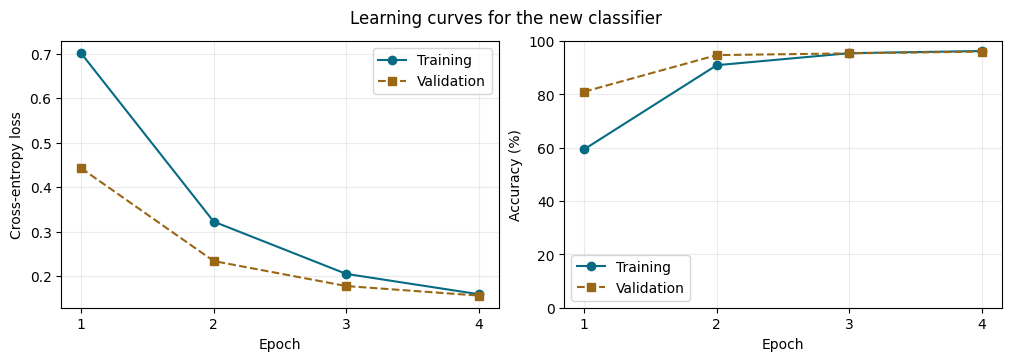

In [23]:
epoch_numbers = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")

for axis, metric, title, scale in [
    (axes[0], "loss", "Cross-entropy loss", 1),
    (axes[1], "accuracy", "Accuracy (%)", 100),
]:
    axis.plot(
        epoch_numbers, [value * scale for value in history[f"train_{metric}"]],
        "o-", color="#076B83", label="Training",
    )
    axis.plot(
        epoch_numbers, [value * scale for value in history[f"val_{metric}"]],
        "s--", color="#9A6715", label="Validation",
    )
    axis.set(xlabel="Epoch", ylabel=title, xticks=list(epoch_numbers))
    axis.grid(alpha=0.25)
    axis.legend()

axes[1].set_ylim(0, 100)
fig.suptitle("Learning curves for the new classifier")
plt.show()

**Step 10:** Build a confusion matrix and inspect predictions

Validation accuracy: 147/153 = 96.1%


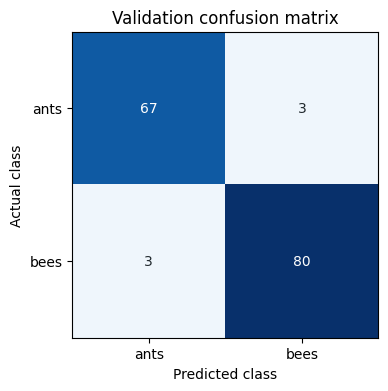

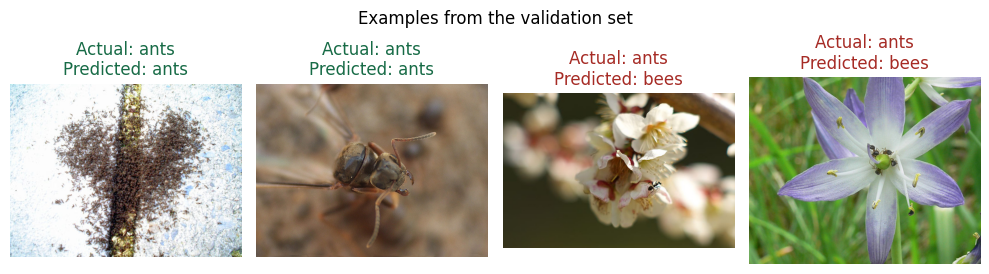

In [24]:
model.eval()
actual_labels = []
predicted_labels = []

with torch.inference_mode():
    for batch_images, batch_labels in val_loader:
        logits = model(batch_images.to(device))
        actual_labels.extend(batch_labels.tolist())
        predicted_labels.extend(logits.argmax(dim=1).cpu().tolist())

matrix = torch.zeros((len(class_names), len(class_names)), dtype=torch.int64)
correct_indices = []
mistake_indices = []
for index, (actual, predicted) in enumerate(zip(actual_labels, predicted_labels)):
    matrix[actual, predicted] += 1
    if actual == predicted:
        correct_indices.append(index)
    else:
        mistake_indices.append(index)

accuracy = matrix.diag().sum().item() / matrix.sum().item()
print(f"Validation accuracy: {len(correct_indices)}/{len(actual_labels)} = {accuracy:.1%}")

fig, axis = plt.subplots(figsize=(4.5, 3.8), layout="constrained")
axis.imshow(matrix.numpy(), cmap="Blues", vmin=0)
axis.set_xticks(range(len(class_names)), class_names)
axis.set_yticks(range(len(class_names)), class_names)
axis.set(xlabel="Predicted class", ylabel="Actual class", title="Validation confusion matrix")
for row in range(len(class_names)):
    for column in range(len(class_names)):
        count = matrix[row, column].item()
        color = "white" if count > matrix.max().item() / 2 else "#20282D"
        axis.text(column, row, count, ha="center", va="center", color=color)
plt.show()

selected_indices = correct_indices[:2] + mistake_indices[:2]
fig, axes = plt.subplots(1, len(selected_indices), figsize=(10, 3), squeeze=False)
for axis, index in zip(axes[0], selected_indices):
    image_path, _ = val_dataset.samples[index]
    with Image.open(image_path) as photo:
        axis.imshow(photo.convert("RGB"))
    actual = actual_labels[index]
    predicted = predicted_labels[index]
    axis.set_title(
        f"Actual: {class_names[actual]}\nPredicted: {class_names[predicted]}",
        color="#176B46" if actual == predicted else "#A62B25",
    )
    axis.axis("off")
fig.suptitle("Examples from the validation set")
fig.tight_layout()
plt.show()

**Step 11:** Classify a single image

ants: 3.5%
bees: 96.5%


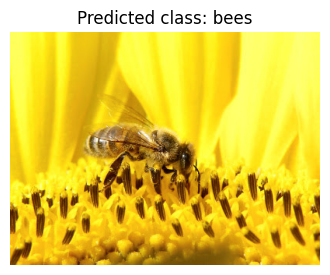

In [26]:
def predict_image(image_path):
    with Image.open(image_path) as photo:
        rgb_image = photo.convert("RGB")

    image_batch = val_transform(rgb_image).unsqueeze(0).to(device)

    model.eval()
    with torch.inference_mode():
        scores = model(image_batch).softmax(dim=1)[0].cpu()

    predicted_id = scores.argmax().item()
    return rgb_image, class_names[predicted_id], scores

image_path = val_dataset.samples[-1][0]
# image_path = "/content/my_insect.jpg"

photo, predicted_class, scores = predict_image(image_path)
for class_name, score in zip(class_names, scores.tolist()):
    print(f"{class_name}: {score:.1%}")

plt.figure(figsize=(4, 3.5))
plt.imshow(photo)
plt.title(f"Predicted class: {predicted_class}")
plt.axis("off")
plt.show()